In [1]:
!pip install -q sentence-transformers faiss-cpu transformers datasets accelerate matplotlib pandas

In [2]:
from datasets import load_dataset
ds = load_dataset("rajpurkar/squad", split="validation").shuffle(seed=42).select(range(300))  # 300 QA pairs
corpus = list(dict.fromkeys(ds["context"]))   # unique passages = our knowledge base
questions = ds["question"][:100]              # evaluate on 100 questions
golds = [a["text"][0] for a in ds["answers"][:100]]   # first gold answer for each question
gold_ctx = ds["context"][:100]
print(len(corpus), "passages |", len(questions), "questions")

README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

275 passages | 100 questions


In [3]:
import faiss, numpy as np
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
emb = embedder.encode(corpus, normalize_embeddings=True, show_progress_bar=True).astype("float32")
index = faiss.IndexFlatIP(emb.shape[1])   # inner product = cosine on normalized vectors
index.add(emb)

def retrieve(q, k=3):
    qe = embedder.encode([q], normalize_embeddings=True).astype("float32")
    scores, idx = index.search(qe, k)
    return [corpus[j] for j in idx[0]], scores[0]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
dev = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained("google/flan-t5-base")
gen = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").to(dev)

def generate(prompt):
    x = tok(prompt, return_tensors="pt", truncation=True, max_length=512).to(dev)
    out = gen.generate(**x, max_new_tokens=32)
    return tok.decode(out[0], skip_special_tokens=True)

def answer_no_rag(q):
    return generate(f"Answer the question briefly.\nQuestion: {q}\nAnswer:")

def answer_rag(q, k=3):
    docs, _ = retrieve(q, k)
    ctx = "\n\n".join(docs)
    return generate(f"Answer the question using the context.\nContext: {ctx}\nQuestion: {q}\nAnswer:")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [5]:
import re, string, collections
def norm(s):
    s = s.lower()
    s = "".join(c for c in s if c not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())
def em(p, gs): return float(any(norm(p) == norm(g) for g in gs))
def f1(p, gs):
    best = 0
    for g in gs:
        pt, gt = norm(p).split(), norm(g).split()
        common = collections.Counter(pt) & collections.Counter(gt)
        n = sum(common.values())
        if n == 0: continue
        pr, rc = n/len(pt), n/len(gt)
        best = max(best, 2*pr*rc/(pr+rc))
    return best

def recall_at_k(k):
    hits = 0
    for q, c in zip(questions, gold_ctx):
        docs, _ = retrieve(q, k)
        hits += c in docs
    return hits / len(questions)

In [6]:
import pandas as pd
rows = []
preds = {}
preds["No-RAG"] = [answer_no_rag(q) for q in questions]
rows.append(["No-RAG", "-", "-",
             np.mean([em(p, g) for p, g in zip(preds["No-RAG"], [[x] for x in golds])]),
             np.mean([f1(p, [g]) for p, g in zip(preds["No-RAG"], golds)])])
for k in [1, 3, 5]:
    p_k = [answer_rag(q, k) for q in questions]
    preds[f"RAG-k{k}"] = p_k
    rows.append([f"RAG k={k}", k, recall_at_k(k),
                 np.mean([em(p, [g]) for p, g in zip(p_k, golds)]),
                 np.mean([f1(p, [g]) for p, g in zip(p_k, golds)])])
results = pd.DataFrame(rows, columns=["Model", "k", "Recall@k", "EM", "F1"])
results

,Model,k,Recall@k,EM,F1
0,No-RAG,-,-,0.02,0.082976
1,RAG k=1,1,0.73,0.58,0.662371
2,RAG k=3,3,0.91,0.33,0.377805
3,RAG k=5,5,0.94,0.02,0.035929


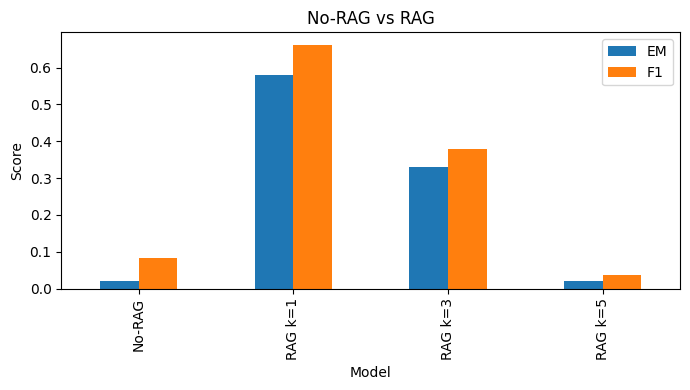

Q: In what year did Massachusetts first require children to be educated in schools?
Gold: 1852
No-RAG: 1898
RAG k=3: 1852
------------------------------------------------------------
Q: When were stromules discovered?
Gold: 1962
No-RAG: 1890
RAG k=3: stromules are very rare in chloroplasts, and are much more common in other plastids like chromoplast
------------------------------------------------------------
Q: Which artist who had a major influence on the Gothic Revival is represented in the V&A's British galleries?
Gold: Horace Walpole
No-RAG: John Lennon
RAG k=3: V&A
------------------------------------------------------------
Q: In 1890, who did the university decide to team up with?
Gold: several regional colleges and universities
No-RAG: the United States
RAG k=3: Newcastle Universities
------------------------------------------------------------
Q: Who got a touchdown making the score 10-7?
Gold: Jonathan Stewart
No-RAG: Bill Belichick
RAG k=3: Manning finished the game 13 of 2

In [7]:
import matplotlib.pyplot as plt
results.plot(x="Model", y=["EM", "F1"], kind="bar", figsize=(7,4), title="No-RAG vs RAG")
plt.ylabel("Score"); plt.tight_layout(); plt.show()

for i in range(5):
    print("Q:", questions[i]); print("Gold:", golds[i])
    print("No-RAG:", preds["No-RAG"][i]); print("RAG k=3:", preds["RAG-k3"][i]); print("-"*60)